# 05 · Simulation study: SIMULATED, method validation only
Parameters are anchored on the Cookie Cats sample size and D7 baseline. **No business conclusions.**

In [1]:
import sys, json, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import Image, display, Markdown
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
FIG = ROOT / "reports" / "figures"

In [2]:
from src.analysis import simulation_study as ss
r = ss.run()
r['anchor']

{'source': 'Cookie Cats sizes and D7 baseline',
 'n_per_arm': 45094,
 'baseline': 0.19020134228187918,
 'real_test_mde_pp': 0.7376150061811748}

## A/A tests (10,000)

In [3]:
{k: v for k, v in r['aa'].items() if k != 'p_values_sample'}

{'sims': 10000,
 'false_positive_rate': 0.0483,
 'mc_ci': [np.float64(0.044097771427254344), np.float64(0.05250222857274566)],
 'p_value_uniformity_ks_p': 0.6523499748085693}

## Power curves: simulation vs analytic

In [4]:
pg = r['power']
sim = pd.DataFrame(pg['simulated_power'], index=pg['n_per_arm']).add_prefix('sim_')
ana = pd.DataFrame(pg['analytic_power'], index=pg['n_per_arm']).add_prefix('analytic_')
pd.concat([sim, ana], axis=1)

,sim_0.0025,sim_0.005,sim_0.0075,sim_0.01,sim_0.015,analytic_0.0025,analytic_0.005,analytic_0.0075,analytic_0.01,analytic_0.015
2000,0.0575,0.0825,0.0900,0.1125,0.2165,0.0546,0.0686,0.0921,0.1255,0.2218
5000,0.0585,0.1030,0.1670,0.2280,0.4730,0.0616,0.0971,0.1577,0.2431,0.4696
10000,0.0760,0.1395,0.2735,0.4365,0.7595,0.0734,0.1459,0.2686,0.4303,0.7592
20000,0.1040,0.2375,0.4565,0.6985,0.9665,0.0974,0.2450,0.4749,0.7134,0.9646
45000,0.1545,0.4735,0.8190,0.9690,1.0000,0.1588,0.4768,0.8120,0.9660,0.9999
80000,0.2560,0.7110,0.9735,0.9985,1.0000,0.2460,0.7175,0.9667,0.9990,1.0000


## Peeking (10 looks)

In [5]:
{k: v for k, v in r['peeking'].items() if k != 'obf_z_bounds'}

{'looks': 10,
 'sims': 10000,
 'n_per_arm_final': 45094,
 'fpr_final_look_only': 0.0533,
 'fpr_peeking_naive': 0.191,
 'fpr_pocock_boundary': 0.0471,
 'pocock_z': 2.5602049902764663,
 'fpr_obrien_fleming': 0.0501,
 'cumulative_naive_fpr_by_look': [0.0492,
  0.0858,
  0.1095,
  0.1261,
  0.1415,
  0.1552,
  0.1664,
  0.1739,
  0.1836,
  0.191]}

## Multiple comparisons

In [6]:
pd.DataFrame(r['multiple_comparisons']['rows'])

,m,fwer_uncorrected,fwer_holm,analytic_uncorrected
0,1,0.0522,0.0522,0.0500
1,5,0.2271,0.0498,0.2262
2,10,0.4005,0.0500,0.4013
3,20,0.6537,0.0500,0.6415
4,44,0.8862,0.0458,0.8953


## Underpowered scenario: a real effect missed

In [7]:
r['underpowered']

{'true_effect_pp': 1.0,
 'n_per_arm': 3000,
 'sims': 10000,
 'share_missed': 0.8351,
 'mean_estimate_when_significant_pp': 2.5012937133616333,
 'exaggeration_ratio_when_significant': 2.5012937133616333,
 'share_wrong_sign_when_significant': 0.010309278350515464}

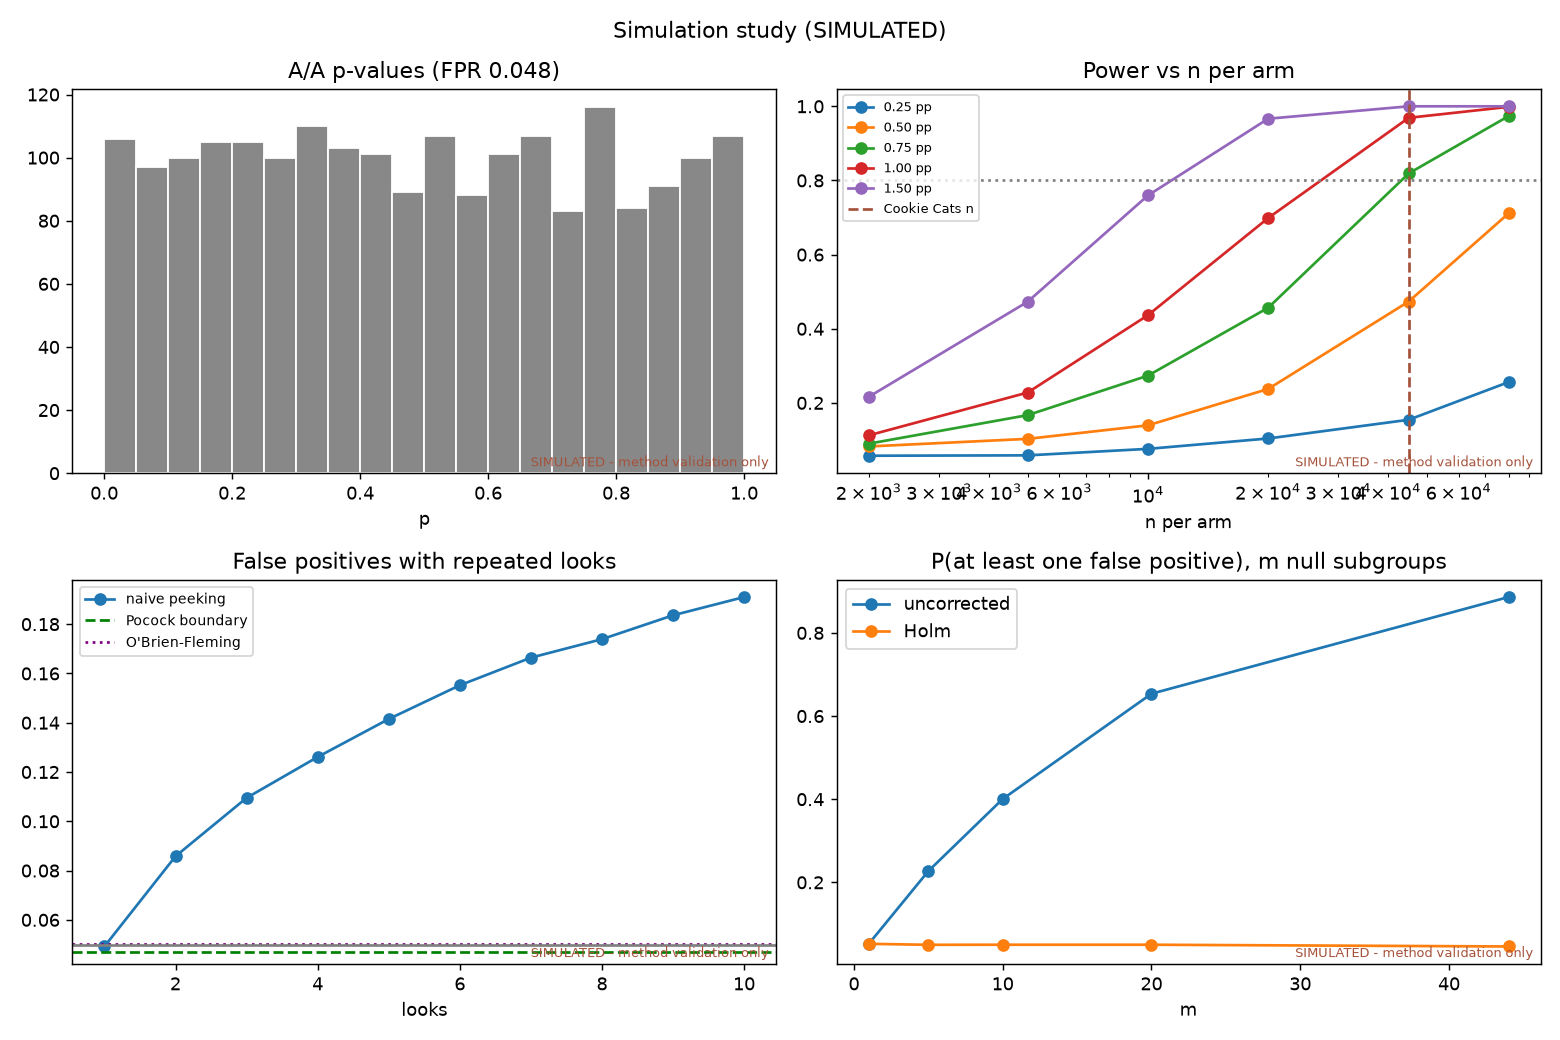

In [8]:
display(Image(FIG / 'simulation_study.png'))

**Reading (simulated).** The A/A false-positive rate is close to 5%, and the p-values are uniform. Simulated power matches the analytic power. Stopping at the first p < 0.05 across 10 looks raises false positives to about 19%, while Pocock and O'Brien-Fleming boundaries hold them near 5%. With 44 null subgroups, at least one false positive is nearly certain without correction (about 89%); Holm keeps that probability near 5%. With 3,000 users per arm, a true 1 pp effect is missed about 84% of the time, and the significant estimates exaggerate it about 2.5 times. A null result is not proof of no effect.